# Moguls of chaos part 2

In the previous post, I described a simple system that exhibits chaos, created by Ed Lorenz. In this post/nb I'll just use that same example and train a neural network with the trajectories of the sleds running down a slope with regular moguls. I want to see if the neural network can still produce the strange attractors and bifurcation diagrams I built in the previous post/nb.

Picking up from where I left. Equations describing the system, assuming that the downslope velocity is constant for all sleds, are given by: 

\begin{align}
\frac{du}{dt} &= 0 \\
\frac{dv}{dt} &= -F \partial_y H - cv, \\

\end{align}

The shape of the slope with the moguls is given by:

$$H(x,y) = -ax - b \ cos(px) \ cos(qy).$$

$a$ is the angle of the slope, $b$ is the height of the bumps, and $q$ and $p$ are spacial frequencies.

In [2]:
import numpy as np
import scipy as scipy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
scipy.integrate.solve_ivp?


Signature:
scipy.integrate.solve_ivp(
    fun,
    t_span,
    y0,
    method='RK45',
    t_eval=None,
    dense_output=False,
    events=None,
    vectorized=False,
    args=None,
    **options,
)
Docstring:
Solve an initial value problem for a system of ODEs.

This function numerically integrates a system of ordinary differential
equations given an initial value::

    dy / dt = f(t, y)
    y(t0) = y0

Here t is a 1-D independent variable (time), y(t) is an
N-D vector-valued function (state), and an N-D
vector-valued function f(t, y) determines the differential equations.
The goal is to find y(t) approximately satisfying the differential
equations, given an initial value y(t0)=y0.

Some of the solvers support integration in the complex domain, but note
that for stiff ODE solvers, the right-hand side must be
complex-differentiable (satisfy Cauchy-Riemann equations [11]_).
To solve a problem in the complex domain, pass y0 with a complex data type.
Another option always available is to 

In [ ]:
def sled(t, X_0):
    """
        sled(t, X_0)

    Right-hand-side of the equations for a sled, with constant downward velocity, 
    going down a slope with moguls.

    X_0 is the the set of initial conditions containing [x, y, u, v], in that oder.
    t optional parameter.
    """

    x0 = np.copy(X_0[0])
    y0 = np.copy(X_0[1])
    u0 = np.copy(X_0[2])
    v0 = np.copy(X_0[3])
    
    g = 9.81
    c = 0.5
    a = 0.25
    #b = 0.5
    p = (2*np.pi)/10.0
    q = (2*np.pi)/4.0
    
    H = -a*x0 - b*np.cos(p*x0)*np.cos(q*y0) 
    H_x = -a + b*p*np.sin(p*x0)*np.cos(q*y0)
    H_xx = b*p**2 * np.cos(p*x0)*np.cos(q*y0)
    H_y = b*q*np.cos(p*x0)*np.sin(q*y0)
    H_yy = b*q**2 * np.cos(p*x0)*np.cos(q*y0)
    H_xy = -b*q*p*np.sin(p*x0)*np.sin(q*y0)
        
    F = (g + H_xx*u0**2 + 2*H_xy*u0*v0 + H_yy*v0**2)/(1 + H_x**2 + H_y**2)
    
    dU = 0
    dV = -F*H_y - c*v0
    
    return np.array([u0, v0, dU, dV])

In [33]:
global b
b = 0.5



In [46]:
solution = scipy.integrate.solve_ivp(sled, [0, 10], [0, 1.45, 1, 0], t_eval=np.linspace(0, 10, 100))

Text(0.5, 0, 'y - Crossslope position (m)')

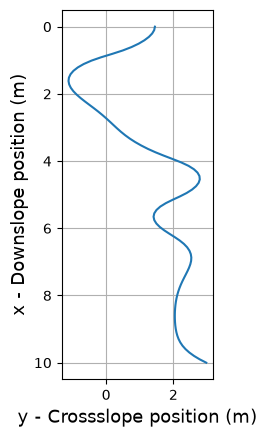

In [47]:
plt.plot(solution.y[1], solution.y[0])
plt.gca().invert_yaxis()
plt.gca().set_aspect('equal', adjustable='box')
plt.grid()
plt.ylabel('x - Downslope position (m)', fontsize =13)
plt.xlabel('y - Crossslope position (m)', fontsize =13)